# Устойчивость управления запасом к сдвигу спроса
## Итоговый проект — трек 2: собственная предметная область
**Ярослав Баев · ysbaev**

Учебное исследование на синтетических данных. Измеряем эффект изменения распределения обучения, не сравниваем названия алгоритмов. Полный протокол ниже зафиксирован до первого обучения.

**Запуск:** в Colab выбрать CPU и «Выполнить всё». Ноутбук самодостаточный: код среды, обучения и оценки включён. Результаты пишутся в `results/`. Для локального запуска: `python -m venv .venv`, затем установка `requirements.txt` и запуск Jupyter. Все шесть моделей обучаются последовательно; графики и результаты отображаются ниже.

**Источники:** [условие LMS](https://apps.skillfactory.ru/learning/course/course-v1:skillfactory+MIFIML-3sem+2026/block-v1:skillfactory+MIFIML-3sem+2026+type@sequential+block@9d8da416c4b54091822898a2c5ffd2e9/block-v1:skillfactory+MIFIML-3sem+2026+type@vertical+block@daef86dcaf004eeab2e1ae299f9917a5), [Gymnasium](https://gymnasium.farama.org/), [рассмотренная готовая среда gym-invmgmt](https://github.com/r2barati/gym-invmgmt).

Многоуровневая среда gym-invmgmt рассмотрена, но для проверки небольшого однотоварного процесса создана своя среда с Gymnasium API; её динамика и инварианты проверяются явно.


# Протокол до обучения — 2026-11-14

## Вопрос и гипотеза
Помогает ли рандомизация среднего спроса во время обучения табличного Q-агента снизить операционные издержки после неожиданного роста спроса?
Гипотеза: обучение на нескольких уровнях спроса снижает стоимость дня после скачка 4→8 по сравнению с обучением только на среднем спросе 4, но может повышать стоимость в исходном режиме. Причина: знакомство с более разнообразными состояниями и необходимостью запаса, а не увеличение вычислительного бюджета.

## Единственный изменяемый фактор
Фиксированное обучение: Poisson(4) каждый день.
Рандомизированное: среднее Poisson выбирается равновероятно из {2,4,6} в начале эпизода и постоянно в течение него.
Все остальные настройки одинаковы, включая seed, бюджет, пространство наблюдений, действия, награду и оценку. Скачок внутри эпизода и средний спрос 8 не встречаются при обучении.

## Модель процесса
Один товар, ёмкость склада 16. Действие 0..16 — целевой запас; пополнение мгновенное, но нельзя удалить излишек. После пополнения реализуется спрос, неудовлетворённый спрос теряется. Издержки: 1 за оставшуюся единицу, 5 за потерянную продажу, 2 за факт заказа. Покупная стоимость не моделируется; задача минимизирует операционные издержки, не прибыль.
Наблюдение: текущий запас и округлённая экспоненциальная оценка спроса (обновляется 0.7*оценка+0.3*спрос, ограничение 0..16). Полный спрос наблюдаем даже при дефиците. Это сильное упрощение, не переносимое напрямую на данные продаж.
Ненаблюдаемый режим спроса делает задачу частично наблюдаемой. Дискретная оценка спроса — ограниченная память, не доказанная достаточная статистика. Теоретические гарантии сходимости табличного Q-learning в MDP здесь не заявляются.
Горизонт 60 дней — административное усечение продолжающейся задачи; bootstrap сохраняется. Начальный запас при обучении равномерно 0..16, оценка спроса 4.

## Алгоритм и бюджет
Табличный Q-learning: gamma=0.95; alpha=0.15; epsilon линейно от 1 до 0.05 за первые 80% бюджета. Q изначально нули. 6000 эпизодов × 60 шагов = 360000 взаимодействий на запуск. Training seeds {11,22,33}; всего шесть запусков. Жадная оценка каждые 300 эпизодов на фиксированных validation seed 10000..10009, отдельно при λ=4 и λ=6. Используется последняя модель, без отбора checkpoint.

## Оценка и контроль утечки
Тестовые demand seeds 20000..20019, initial stock {0,8,16}; 60 эпизодов на сценарий на модель. Те же реализации спроса у всех политик. Training, validation и test seed не пересекаются.
Сценарии: постоянный спрос 4 (ID), постоянный 6 (встречался только рандомизированному агенту), постоянный 8 (OOD), скачок 4→8 после 30 дней (основной OOD), скачок 4→2 (дополнительный стресс-тест).
Главная метрика: средние издержки за день 31..60 сценария 4→8. Эффект: cost(fixed)-cost(randomized), положительное значение в пользу рандомизации. Сначала усредняем эпизоды внутри training seed, затем показываем среднее и sample SD по трём training seeds; также все три парные разности. Это описание трёх запусков, не доказательство статистической значимости.
Дополнительные метрики: стоимость всего эпизода/дня, доля удовлетворённого спроса, средний остаток, доля дней с дефицитом, нижний дециль возврата.
Бейзлайны: случайный target 0..16; фиксированный base-stock, выбранный из 0..16 на validation λ=4; адаптивная эвристика target=ceil(estimate+sqrt(max(estimate,1))), без настройки на тесте. Они не получают скрытого режима и будущего спроса.
Визуализация: кривая validation-return; средняя стоимость по сценариям; траектория первого training seed на заранее фиксированном test seed 20000 и начальном запасе 8; карты политики. Отрицательный результат сохраняется. Никакой настройки после просмотра теста.

## Границы
Синтетический спрос, нулевой lead time, один SKU, фиксированная ёмкость, несмещённое наблюдение спроса, только три training seed. Нет вывода о превосходстве RL над оптимизацией запасов вообще.

## Выбор среды
Рассмотрен https://github.com/r2barati/gym-invmgmt — готовая многоуровневая модель с поставками, lead time и непрерывными действиями. Для изоляции одного фактора и полностью проверяемой небольшой среды выбран собственный однотоварный процесс с Gymnasium API. Это соответствует треку 2. Новый алгоритм не предлагается.


In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec('gymnasium') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'gymnasium==1.4.0'])


In [2]:
%matplotlib inline

## Imports

In [3]:
from pathlib import Path
import json, time, sys, subprocess, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
from gymnasium.utils.env_checker import check_env
from IPython.display import display, Markdown

OUT = Path('results'); OUT.mkdir(exist_ok=True)
TRAIN_SEEDS = [11, 22, 33]
VALID_SEEDS = list(range(10000, 10010))
TEST_SEEDS = list(range(20000, 20020))
EPISODES, HORIZON, CAPACITY = 6000, 60, 16
SCENARIOS = {'ID 4':(4,4), 'Seen 6':(6,6), 'OOD 8':(8,8), 'Shock 4→8':(4,8), 'Drop 4→2':(4,2)}
assert not set(TRAIN_SEEDS) & set(VALID_SEEDS)
assert not set(VALID_SEEDS) & set(TEST_SEEDS)
plt.rcParams.update({'figure.dpi':120, 'axes.spines.top':False, 'axes.spines.right':False})



## Environment

In [4]:
class InventoryEnv(gym.Env):
    """Lost-sales inventory. Hidden demand regime; public rounded demand estimate."""
    metadata = {'render_modes':[]}
    def __init__(self, randomized=False, schedule=None, horizon=HORIZON):
        super().__init__()
        self.randomized, self.schedule, self.horizon = randomized, schedule, horizon
        self.action_space = spaces.Discrete(CAPACITY+1)
        self.observation_space = spaces.MultiDiscrete([CAPACITY+1, CAPACITY+1])
    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        options = options or {}
        if self.schedule is None:
            level = int(self.np_random.choice([2,4,6])) if self.randomized else 4
            levels = np.full(self.horizon, level)
        else:
            levels = np.array([self.schedule[0] if t < self.horizon//2 else self.schedule[1] for t in range(self.horizon)])
        # All exogenous randomness is generated before any action.
        self.demands = self.np_random.poisson(levels)
        self.stock = int(options['stock']) if 'stock' in options else int(self.np_random.integers(CAPACITY+1))
        self.estimate, self.t = 4, 0
        return np.array([self.stock, self.estimate], dtype=np.int64), {}
    def step(self, action):
        assert self.action_space.contains(action)
        if self.t >= self.horizon:
            raise RuntimeError('reset required after truncation')
        order = max(0, int(action)-self.stock)
        available = self.stock + order
        demand = int(self.demands[self.t])
        sold = min(available, demand)
        lost = demand-sold
        self.stock = available-sold
        cost = float(self.stock + 5*lost + 2*(order>0))
        self.estimate = int(np.clip(np.rint(0.7*self.estimate+0.3*demand), 0, CAPACITY))
        self.t += 1
        info = dict(day=self.t, demand=demand, sold=sold, lost=lost, stock=self.stock,
                    available=available, order=order, cost=cost, estimate=self.estimate)
        return np.array([self.stock,self.estimate], dtype=np.int64), -cost, False, self.t >= self.horizon, info

def td_target(reward, next_q, terminated, gamma=0.95):
    return reward + gamma*(not terminated)*np.max(next_q)



## Independent checks

In [5]:
check_env(InventoryEnv(), skip_render_check=True)
e = InventoryEnv(horizon=2)
e.reset(seed=1, options={'stock':3}); e.demands = np.array([7,0])
obs,r,term,trunc,info = e.step(5)
assert (info['order'],info['sold'],info['lost'],info['stock'],r)==(2,5,2,0,-12)
assert not term and not trunc
obs,r,term,trunc,info = e.step(4)
assert r == -6 and info['stock']==4 and trunc and not term
assert td_target(1,np.array([10,3]),False,0.5)==6
assert td_target(2,np.array([10,3]),True,0.5)==2
for seed in [1,2,3]:
    e1,e2 = InventoryEnv(schedule=(4,8)),InventoryEnv(schedule=(4,8))
    e1.reset(seed=seed,options={'stock':0}); e2.reset(seed=seed,options={'stock':16})
    assert np.array_equal(e1.demands,e2.demands)
    for t in range(HORIZON):
        _,r,_,_,x=e1.step(t%17)
        assert 0<=x['stock']<=16 and x['sold']+x['lost']==x['demand']
        assert x['available']-x['sold']==x['stock'] and r==-x['cost']
print('PASS: Gymnasium API; demand coupling; inventory conservation; hand-computed cost; terminal/bootstrap handling.')



PASS: Gymnasium API; demand coupling; inventory conservation; hand-computed cost; terminal/bootstrap handling.


## Evaluation helpers

In [6]:

def rollout(policy, schedule, seed, stock=8):
    env = InventoryEnv(schedule=schedule)
    obs,_ = env.reset(seed=seed,options={'stock':stock})
    rng = np.random.default_rng(seed+500000)
    rows=[]
    for _ in range(HORIZON):
        if isinstance(policy, np.ndarray):
            action=int(np.argmax(policy[tuple(obs)]))
        elif policy == 'random':
            action=int(rng.integers(17))
        elif policy == 'adaptive':
            action=int(np.clip(np.ceil(obs[1]+np.sqrt(max(obs[1],1))),0,16))
        else:
            action=int(policy)
        obs,_,term,trunc,info=env.step(action)
        rows.append(info)
        if term or trunc: break
    return pd.DataFrame(rows)

def episode_metrics(frame):
    return dict(cost_day=frame.cost.mean(), post_cost=frame.cost.iloc[30:].mean(),
                fill_rate=frame.sold.sum()/max(frame.demand.sum(),1),
                stock=frame.stock.mean(), stockout_rate=(frame.lost>0).mean(),
                episode_return=-frame.cost.sum())

def validation_return(q, level):
    return np.mean([-rollout(q,(level,level),s).cost.sum() for s in VALID_SEEDS])



## Training

In [7]:

def train(condition, seed):
    env=InventoryEnv(randomized=(condition=='randomized'))
    rng=np.random.default_rng(seed)
    q=np.zeros((17,17,17),dtype=np.float64)
    history=[]
    start=time.perf_counter()
    for episode in range(EPISODES+1):
        if episode%300==0:
            vals={str(level):validation_return(q,level) for level in [4,6]}
            history.append(dict(condition=condition,seed=seed,steps=episode*HORIZON,
                                validation_4=vals['4'],validation_6=vals['6']))
            if episode%1500==0:
                print(condition,seed,'episodes',episode,'validation returns',vals,flush=True)
            np.savez_compressed(OUT/f'{condition}_{seed}.npz',q=q,episodes=episode)
            pd.DataFrame(history).to_csv(OUT/f'learning_{condition}_{seed}.csv',index=False)
        if episode==EPISODES: break
        obs,_=env.reset(seed=seed*1000000+episode)
        epsilon=max(0.05,1-0.95*episode/(0.8*EPISODES))
        for step in range(HORIZON):
            state=tuple(obs)
            action=int(rng.integers(17)) if rng.random()<epsilon else int(np.argmax(q[state]))
            nxt,reward,terminated,truncated,_=env.step(action)
            idx=state+(action,)
            q[idx] += 0.15*(td_target(reward,q[tuple(nxt)],terminated)-q[idx])
            obs=nxt
            if terminated or truncated: break
    seconds=time.perf_counter()-start
    return q,history,dict(condition=condition,seed=seed,seconds=seconds,steps=EPISODES*HORIZON)

models={}; histories=[]; timing=[]
for condition in ['fixed','randomized']:
    for seed in TRAIN_SEEDS:
        q,h,t=train(condition,seed)
        models[(condition,seed)]=q; histories.extend(h); timing.append(t)
learning=pd.DataFrame(histories); runtime=pd.DataFrame(timing)
learning.to_csv(OUT/'learning.csv',index=False); runtime.to_csv(OUT/'runtime.csv',index=False)
display(runtime)



fixed 11 episodes 0 validation returns {'4': np.float64(-1161.7), '6': np.float64(-1757.2)}


fixed 11 episodes 1500 validation returns {'4': np.float64(-352.9), '6': np.float64(-523.7)}


fixed 11 episodes 3000 validation returns {'4': np.float64(-342.0), '6': np.float64(-550.9)}


fixed 11 episodes 4500 validation returns {'4': np.float64(-370.4), '6': np.float64(-535.4)}


fixed 11 episodes 6000 validation returns {'4': np.float64(-324.3), '6': np.float64(-515.9)}


fixed 22 episodes 0 validation returns {'4': np.float64(-1161.7), '6': np.float64(-1757.2)}


... (21 outputs left out)

randomized 33 episodes 3000 validation returns {'4': np.float64(-385.1), '6': np.float64(-431.9)}


randomized 33 episodes 4500 validation returns {'4': np.float64(-363.2), '6': np.float64(-428.1)}


randomized 33 episodes 6000 validation returns {'4': np.float64(-373.5), '6': np.float64(-489.2)}


,condition,seed,seconds,steps
0,fixed,11,4.210929,360000
1,fixed,22,4.331039,360000
2,fixed,33,4.292032,360000
3,randomized,11,4.252007,360000
4,randomized,22,4.472575,360000
5,randomized,33,4.230926,360000


## Baseline validation — no test data used

In [8]:
base_validation=[]
for target in range(17):
    costs=[rollout(target,(4,4),s,stock).cost.mean() for s in VALID_SEEDS for stock in [0,8,16]]
    base_validation.append(dict(target=target,validation_cost=np.mean(costs)))
base_validation=pd.DataFrame(base_validation)
BASE_TARGET=int(base_validation.loc[base_validation.validation_cost.idxmin(),'target'])
base_validation.to_csv(OUT/'base_stock_validation.csv',index=False)
print('Base-stock target selected only on ID validation:',BASE_TARGET)



Base-stock target selected only on ID validation: 6


## Frozen final evaluation

In [9]:
records=[]
policies=[(condition,seed,q) for (condition,seed),q in models.items()]
policies += [('random',-1,'random'),('base_stock',-1,BASE_TARGET),('adaptive',-1,'adaptive')]
for name,training_seed,policy in policies:
    for scenario,schedule in SCENARIOS.items():
        for demand_seed in TEST_SEEDS:
            for initial_stock in [0,8,16]:
                frame=rollout(policy,schedule,demand_seed,initial_stock)
                records.append(dict(policy=name,training_seed=training_seed,scenario=scenario,
                                    demand_seed=demand_seed,initial_stock=initial_stock,**episode_metrics(frame)))
results=pd.DataFrame(records)
results.to_csv(OUT/'episodes.csv',index=False)
metrics=['cost_day','post_cost','fill_rate','stock','stockout_rate','episode_return']
per_seed=results.groupby(['policy','training_seed','scenario'])[metrics].mean().reset_index()
per_seed.to_csv(OUT/'seed_means.csv',index=False)
summary=per_seed.groupby(['policy','scenario'])[metrics].agg(['mean','std'])
summary.to_csv(OUT/'summary.csv')
# lower tail includes episode stochasticity and initial stock; not independent training replicates
q10=results.groupby(['policy','scenario']).episode_return.quantile(0.1).rename('return_q10')
q10.to_csv(OUT/'return_q10.csv')
display(summary.round(3))
main=per_seed[(per_seed.scenario=='Shock 4→8') & per_seed.policy.isin(['fixed','randomized'])]
paired=main.pivot(index='training_seed',columns='policy',values='post_cost')
paired['saving']=paired.fixed-paired.randomized
paired.to_csv(OUT/'primary_effect.csv')
display(paired.round(3))
print('PRIMARY: paired savings mean ± sample SD:',paired.saving.mean(),paired.saving.std(ddof=1))



cost_day        post_cost        fill_rate         stock  \
                         mean    std      mean    std      mean    std   mean   
policy     scenario                                                             
adaptive   Drop 4→2     4.785    NaN     4.228    NaN     0.960    NaN  2.632   
           ID 4         5.370    NaN     5.398    NaN     0.948    NaN  2.639   
           OOD 8        7.075    NaN     7.197    NaN     0.952    NaN  3.235   
           Seen 6       6.206    NaN     6.230    NaN     0.958    NaN  3.102   
           Shock 4→8    6.284    NaN     7.227    NaN     0.948    NaN  2.941   
base_stock Drop 4→2     5.474    NaN     5.798    NaN     0.970    NaN  3.217   
           ID 4         5.173    NaN     5.197    NaN     0.953    NaN  2.315   
           OOD 8       13.824    NaN    14.193    NaN     0.713    NaN  0.418   
           Seen 6       7.381    NaN     7.483    NaN     0.853    NaN  1.059   
           Shock 4→8    9.471    NaN    13.792    NaN     0.795    NaN  1.387   
fixed      Drop 4→2     5.987  0.227     6.412  0.572     0.968  0.012  4.411   
           ID 4         5.559  0.107     5.557  0.152     0.968  0.004  3.484   
           OOD 8       21.950  1.962    23.604  1.995     0.523  0.051  1.610   
           Seen 6       8.168  0.510     8.466  0.497     0.904  0.020  3.820   
           Shock 4→8   13.254  1.095    20.945  2.089     0.690  0.037  2.571   
random     Drop 4→2     9.027    NaN     9.865    NaN     0.964    NaN  7.479   
           ID 4         8.124    NaN     8.060    NaN     0.948    NaN  5.892   
           OOD 8       13.301    NaN    13.448    NaN     0.771    NaN  2.582   
           Seen 6       9.418    NaN     9.577    NaN     0.864    NaN  3.921   
           Shock 4→8   10.709    NaN    13.230    NaN     0.832    NaN  4.263   
randomized Drop 4→2     5.633  0.258     5.135  0.240     0.968  0.012  4.053   
           ID 4         6.084  0.256     6.037  0.234     0.962  0.015  4.051   
           OOD 8       11.103  0.870    12.055  1.172     0.838  0.021  3.075   
           Seen 6       7.488  0.639     7.698  0.714     0.935  0.019  4.087   
           Shock 4→8    8.495  0.520    10.859  1.025     0.886  0.020  3.645   

                            stockout_rate        episode_return           
                        std          mean    std           mean      std  
policy     scenario                                                       
adaptive   Drop 4→2     NaN         0.071    NaN       -287.083      NaN  
           ID 4         NaN         0.111    NaN       -322.183      NaN  
           OOD 8        NaN         0.147    NaN       -424.517      NaN  
           Seen 6       NaN         0.120    NaN       -372.367      NaN  
           Shock 4→8    NaN         0.136    NaN       -377.033      NaN  
base_stock Drop 4→2     NaN         0.053    NaN       -328.450      NaN  
           ID 4         NaN         0.108    NaN       -310.400      NaN  
           OOD 8        NaN         0.674    NaN       -829.417      NaN  
           Seen 6       NaN         0.361    NaN       -442.833      NaN  
           Shock 4→8    NaN         0.392    NaN       -568.250      NaN  
fixed      Drop 4→2   0.318         0.058  0.017       -359.228   13.648  
           ID 4       0.236         0.073  0.010       -333.567    6.402  
           OOD 8      0.672         0.643  0.095      -1316.983  117.736  
           Seen 6     0.633         0.210  0.043       -490.067   30.599  
           Shock 4→8  0.416         0.352  0.050       -795.217   65.728  
random     Drop 4→2     NaN         0.044    NaN       -541.600      NaN  
           ID 4         NaN         0.086    NaN       -487.450      NaN  
           OOD 8        NaN         0.408    NaN       -798.033      NaN  
           Seen 6       NaN         0.244    NaN       -565.100      NaN  
           Shock 4→8    NaN         0.248    NaN       -642.550      NaN  
randomized Drop 4→2   0.190

policy,fixed,randomized,saving
training_seed,,,
11,22.043,11.248,10.795
22,18.537,11.632,6.905
33,22.256,9.697,12.559


PRIMARY: paired savings mean ± sample SD: 10.086481481481483 2.893040677581273


## Learning curves

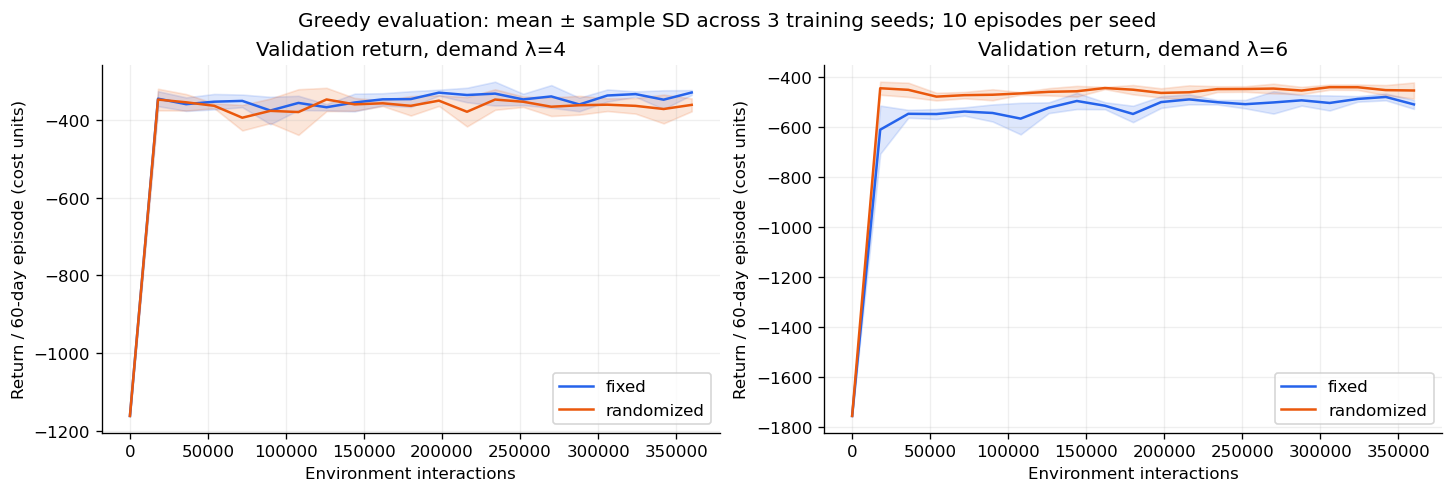

In [10]:
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for ax,level in zip(axes,[4,6]):
    for condition,color in [('fixed','#2563eb'),('randomized','#ea580c')]:
        g=learning[learning.condition==condition].groupby('steps')[f'validation_{level}'].agg(['mean','std'])
        x=g.index.to_numpy(); m=g['mean'].to_numpy(); s=g['std'].to_numpy()
        ax.plot(x,m,label=condition,color=color); ax.fill_between(x,m-s,m+s,color=color,alpha=.15)
    ax.set(title=f'Validation return, demand λ={level}',xlabel='Environment interactions',ylabel='Return / 60-day episode (cost units)')
    ax.legend(); ax.grid(alpha=.2)
fig.suptitle('Greedy evaluation: mean ± sample SD across 3 training seeds; 10 episodes per seed')
fig.savefig(OUT/'learning.png'); plt.show()



## Comparison plots

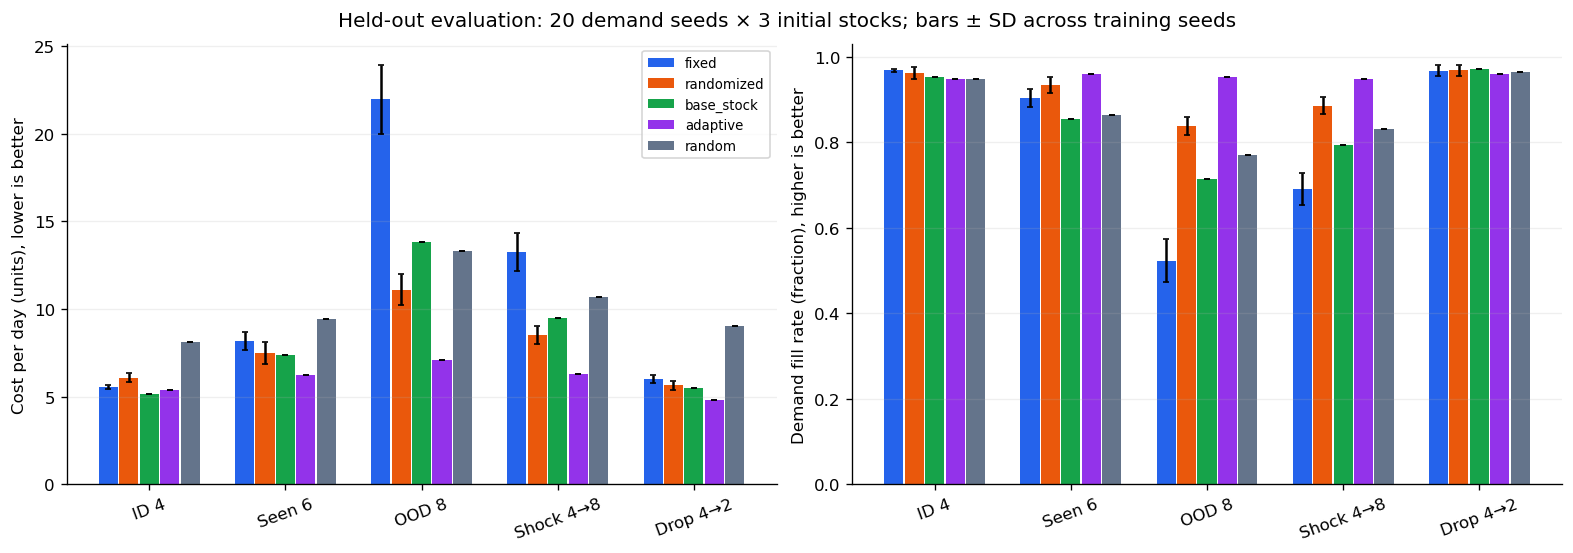

In [11]:
fig,axes=plt.subplots(1,2,figsize=(13,4.5),layout='constrained')
colors={'fixed':'#2563eb','randomized':'#ea580c','base_stock':'#16a34a','adaptive':'#9333ea','random':'#64748b'}
for ax,metric,label in zip(axes,['cost_day','fill_rate'],['Cost per day (units), lower is better','Demand fill rate (fraction), higher is better']):
    for i,name in enumerate(colors):
        g=per_seed[per_seed.policy==name].groupby('scenario')[metric].agg(['mean','std']).reindex(SCENARIOS)
        pos=np.arange(len(SCENARIOS))+(i-2)*.15
        ax.bar(pos,g['mean'],width=.14,label=name,color=colors[name],yerr=g['std'].fillna(0),capsize=2)
    ax.set_xticks(np.arange(len(SCENARIOS)),SCENARIOS,rotation=20)
    ax.set_ylabel(label); ax.grid(axis='y',alpha=.2)
axes[0].legend(fontsize=8)
fig.suptitle('Held-out evaluation: 20 demand seeds × 3 initial stocks; bars ± SD across training seeds')
fig.savefig(OUT/'comparison.png'); plt.show()



## Predetermined behavior example — no best-episode selection

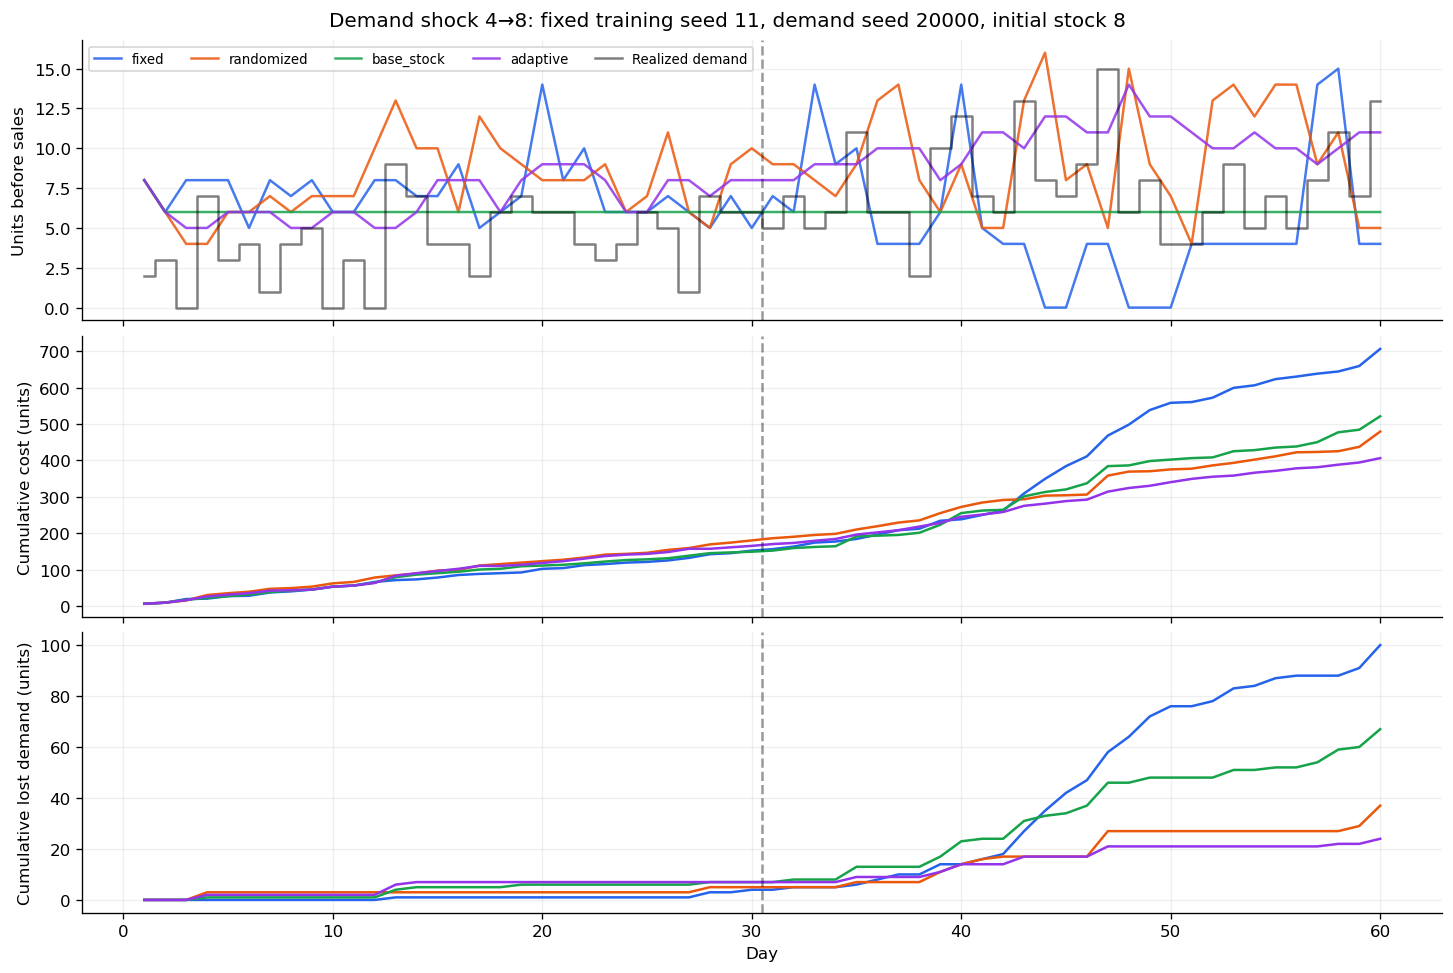

In [12]:
fig,axes=plt.subplots(3,1,figsize=(12,8),sharex=True,layout='constrained')
trajectory=[]
for name,policy in [('fixed',models[('fixed',11)]),('randomized',models[('randomized',11)]),('base_stock',BASE_TARGET),('adaptive','adaptive')]:
    f=rollout(policy,(4,8),20000,8); f['policy']=name; trajectory.append(f)
    axes[0].plot(f.day,f.available,label=name,color=colors[name],alpha=.85)
    axes[1].plot(f.day,f.cost.cumsum(),label=name,color=colors[name])
    axes[2].plot(f.day,f.lost.cumsum(),label=name,color=colors[name])
axes[0].step(f.day,f.demand,label='Realized demand',color='black',alpha=.5,where='mid')
for ax in axes:
    ax.axvline(30.5,color='black',ls='--',alpha=.4); ax.grid(alpha=.2)
axes[0].set_ylabel('Units before sales'); axes[0].legend(ncol=5,fontsize=8)
axes[1].set_ylabel('Cumulative cost (units)'); axes[2].set_ylabel('Cumulative lost demand (units)'); axes[2].set_xlabel('Day')
fig.suptitle('Demand shock 4→8: fixed training seed 11, demand seed 20000, initial stock 8')
fig.savefig(OUT/'trajectory.png'); plt.show()
pd.concat(trajectory).to_csv(OUT/'trajectory.csv',index=False)



## Policy diagnostics

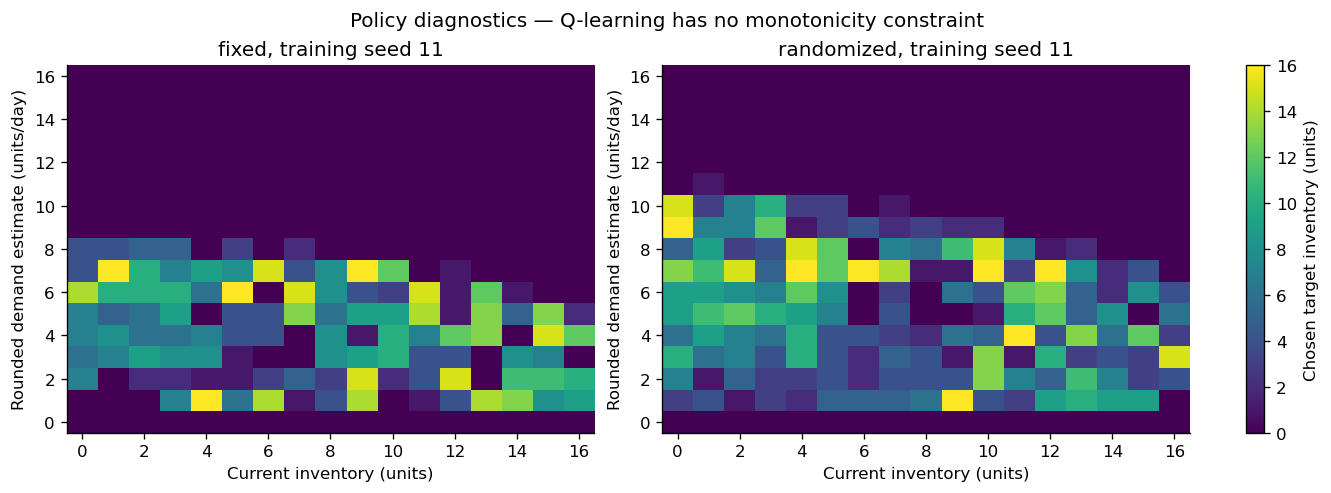

In [13]:
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
for ax,condition in zip(axes,['fixed','randomized']):
    policy=models[(condition,11)].argmax(axis=2)
    im=ax.imshow(policy.T,origin='lower',vmin=0,vmax=16,cmap='viridis',aspect='auto')
    ax.set(title=f'{condition}, training seed 11',xlabel='Current inventory (units)',ylabel='Rounded demand estimate (units/day)')
fig.colorbar(im,ax=axes,label='Chosen target inventory (units)')
fig.suptitle('Policy diagnostics — Q-learning has no monotonicity constraint')
fig.savefig(OUT/'policy.png'); plt.show()



## Numeric analysis and reproducibility

In [14]:
mean_effect=float(paired.saving.mean()); sd_effect=float(paired.saving.std(ddof=1))
relative=100*mean_effect/paired.fixed.mean()
id_means=per_seed[per_seed.scenario=='ID 4'].groupby('policy').cost_day.mean()
shock_means=per_seed[per_seed.scenario=='Shock 4→8'].groupby('policy').post_cost.mean()
verdict='поддерживается по направлению среднего эффекта' if mean_effect>0 else 'не поддерживается по направлению среднего эффекта'
report=f'''## Результаты и интерпретация

Основная гипотеза **{verdict}**: после скачка спроса 4→8 средняя парная экономия randomized против fixed составляет **{mean_effect:.3f} ± {sd_effect:.3f} единицы издержек/день** (sample SD по 3 training seeds), или {relative:.1f}% стоимости fixed. Все три парные разности: {paired.saving.round(3).tolist()}.

Обычный спрос λ=4: fixed {id_means['fixed']:.3f}, randomized {id_means['randomized']:.3f} единицы/день. Цена рандомизации в ID: {id_means['randomized']-id_means['fixed']:+.3f} единицы/день.

После скачка 4→8: fixed {shock_means['fixed']:.3f}, randomized {shock_means['randomized']:.3f}, base-stock {shock_means['base_stock']:.3f}, adaptive {shock_means['adaptive']:.3f}, random {shock_means['random']:.3f} единицы/день. Превосходство над random само по себе не доказывает полезность RL: важны сравнения с двумя эвристиками.

Рандомизация расширяет покрытие состояний с высоким спросом. Но Q-таблица может плохо оценивать редкие пары «состояние–действие», а фиксированный коэффициент обучения сохраняет шум оценок. Карты политики показывают, насколько решения согласованы в соседних состояниях. Из одного графика нельзя установить механизм причинно; для этого нужен дополнительный эксперимент с посещаемостью состояний или памятью.

Основной эффект относится только к этим шести запускам и синтетической среде. Три training seed — небольшая выборка; показанный SD не является доверительным интервалом. Эпизоды с разным начальным запасом разделяют один поток спроса и не считаются независимыми повторами обучения. Базовая эвристика настроена только на ID validation; адаптивная эвристика задана до теста. Нельзя утверждать превосходство над лучшей возможной эвристикой.

### Ограничения и следующие проверки

- Режим спроса скрыт; округлённая оценка спроса не гарантирует марковость. Здесь Q-learning — практический метод, а не применение теоремы сходимости к MDP.
- Полный спрос наблюдается, включая потерянные продажи; реальная система часто видит только продажи. Нет lead time, закупочной цены, возвратов, сезонности и ограничений поставщика.
- Учебная цель — операционные издержки; это не денежная прибыль реального бизнеса.
- Влияние обучения при λ=6 неотделимо от улучшения покрытия высоких оценок спроса. Это часть исследуемого изменения распределения, но не доказательство универсальной устойчивости.
- Следующий эксперимент: больше training seeds, задержка поставки и цензурированный спрос; отдельно сравнить более длинную память. Не менять постановку после просмотра этого теста.

### Воспроизводимость

Все модели — последние checkpoints после {EPISODES*HORIZON:,} взаимодействий; отбор по test не проводился. Общий бюджет — {6*EPISODES*HORIZON:,} взаимодействий, без шагов отдельной оценки. Время шести запусков: {runtime.seconds.sum():.1f} секунды на текущей машине. Финальная таблица включает {len(results)} эпизодов. Обучение/оценка CPU, без платных API. Trajectory зафиксирована заранее и не выбиралась по красоте.
'''
display(Markdown(report)); (OUT/'analysis.md').write_text(report,encoding='utf-8')
from importlib.metadata import distributions
freeze = '\n'.join(sorted({f"{d.metadata['Name']}=={d.version}" for d in distributions() if d.metadata['Name']})) + '\n'
(OUT/'pip-freeze.txt').write_text(freeze)
metadata={'python':sys.version,'platform':platform.platform(),'training_seeds':TRAIN_SEEDS,'validation_seeds':VALID_SEEDS,'test_seeds':TEST_SEEDS,'episodes':EPISODES,'horizon':HORIZON,'gymnasium':gym.__version__,'numpy':np.__version__,'pandas':pd.__version__}
(OUT/'metadata.json').write_text(json.dumps(metadata,ensure_ascii=False,indent=2))
print(json.dumps(metadata,ensure_ascii=False,indent=2))
print('Full pip freeze saved to results/pip-freeze.txt')


## Результаты и интерпретация

Основная гипотеза **поддерживается по направлению среднего эффекта**: после скачка спроса 4→8 средняя парная экономия randomized против fixed составляет **10.086 ± 2.893 единицы издержек/день** (sample SD по 3 training seeds), или 48.2% стоимости fixed. Все три парные разности: [10.795, 6.905, 12.559].

Обычный спрос λ=4: fixed 5.559, randomized 6.084 единицы/день. Цена рандомизации в ID: +0.525 единицы/день.

После скачка 4→8: fixed 20.945, randomized 10.859, base-stock 13.792, adaptive 7.227, random 13.230 единицы/день. Превосходство над random само по себе не доказывает полезность RL: важны сравнения с двумя эвристиками.

Рандомизация расширяет покрытие состояний с высоким спросом. Но Q-таблица может плохо оценивать редкие пары «состояние–действие», а фиксированный коэффициент обучения сохраняет шум оценок. Карты политики показывают, насколько решения согласованы в соседних состояниях. Из одного графика нельзя установить механизм причинно; для этого нужен дополнительный эксперимент с посещаемостью состояний или памятью.

Основной эффект относится только к этим шести запускам и синтетической среде. Три training seed — небольшая выборка; показанный SD не является доверительным интервалом. Эпизоды с разным начальным запасом разделяют один поток спроса и не считаются независимыми повторами обучения. Базовая эвристика настроена только на ID validation; адаптивная эвристика задана до теста. Нельзя утверждать превосходство над лучшей возможной эвристикой.

### Ограничения и следующие проверки

- Режим спроса скрыт; округлённая оценка спроса не гарантирует марковость. Здесь Q-learning — практический метод, а не применение теоремы сходимости к MDP.
- Полный спрос наблюдается, включая потерянные продажи; реальная система часто видит только продажи. Нет lead time, закупочной цены, возвратов, сезонности и ограничений поставщика.
- Учебная цель — операционные издержки; это не денежная прибыль реального бизнеса.
- Влияние обучения при λ=6 неотделимо от улучшения покрытия высоких оценок спроса. Это часть исследуемого изменения распределения, но не доказательство универсальной устойчивости.
- Следующий эксперимент: больше training seeds, задержка поставки и цензурированный спрос; отдельно сравнить более длинную память. Не менять постановку после просмотра этого теста.

### Воспроизводимость

Все модели — последние checkpoints после 360,000 взаимодействий; отбор по test не проводился. Общий бюджет — 2,160,000 взаимодействий, без шагов отдельной оценки. Время шести запусков: 25.8 секунды на текущей машине. Финальная таблица включает 2700 эпизодов. Обучение/оценка CPU, без платных API. Trajectory зафиксирована заранее и не выбиралась по красоте.


{
  "python": "3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 11:23:37) [Clang 14.0.6 ]",
  "platform": "macOS-15.6.1-arm64-arm-64bit-Mach-O",
  "training_seeds": [
    11,
    22,
    33
  ],
  "validation_seeds": [
    10000,
    10001,
    10002,
    10003,
    10004,
    10005,
    10006,
    10007,
    10008,
    10009
  ],
  "test_seeds": [
    20000,
    20001,
    20002,
    20003,
    20004,
    20005,
    20006,
    20007,
    20008,
    20009,
    20010,
    20011,
    20012,
    20013,
    20014,
    20015,
    20016,
    20017,
    20018,
    20019
  ],
  "episodes": 6000,
  "horizon": 60,
  "gymnasium": "1.4.0",
  "numpy": "2.1.3",
  "pandas": "2.2.3"
}
Full pip freeze saved to results/pip-freeze.txt


In [15]:
print(freeze)  # Полный снимок зависимостей среды исполнения

absl-py==2.3.1
aext-assistant==4.20.0
aext-assistant-server==4.20.0
aext-core==4.20.0
aext-core-server==4.20.0
aext-panels==4.20.0
aext-panels-server==4.20.0
aext-project-filebrowser-server==4.20.0
aext-share-notebook==4.20.0
aext-share-notebook-server==4.20.0
aext-shared==4.20.0
aext-toolbox==4.20.0
aext_environments_server==4.20.0
aiobotocore==2.19.0
aiohappyeyeballs==2.4.4
aiohttp==3.11.10
aioitertools==0.7.1
aiosignal==1.2.0
alabaster==0.7.16
alembic==1.17.1
altair==5.5.0
anaconda-anon-usage==0.7.1
anaconda-auth==0.8.6
anaconda-catalogs==0.2.0
anaconda-cli-base==0.5.2
anaconda-client==1.13.0
anaconda-navigator==2.6.6
anaconda-project==0.11.1
annotated-types==0.6.0
antlr4-python3-runtime==4.9.3
anyio==4.7.0
appdirs==1.4.4
applaunchservices==0.3.0
appnope==0.1.3
appscript==1.3.0
archspec==0.2.3
argon2-cffi==21.3.0
argon2-cffi-bindings==21.2.0
arrow==1.3.0
astroid==3.3.8
astropy==7.0.0
astropy-iers-data==0.2025.1.13.0.34.51
asttokens==3.0.0
astunparse==1.6.3
async-lru==2.0.4
asyncssh=

## Что означает результат на практике

**Гипотеза о пользе разнообразного обучения поддерживается в этом эксперименте, но превосходство RL над простой предметной стратегией не показано.**

1. После скачка спроса издержки randomized составляют 10.859 против 20.945 у fixed: снижение 48.2%. Все три парных эффекта положительны.
2. Адаптивная эвристика достигает 7.227: randomized дороже неё примерно на 50.3%. Для этой простой модели усложнение до RL не оправдано полученным качеством.
3. При обычном спросе randomized дороже fixed примерно на 9.4%. Это наблюдаемая цена устойчивости.
4. На заранее выбранной траектории fixed несколько дней остаётся без товара при высоком спросе; накопленный неудовлетворённый спрос быстро растёт. Randomized уменьшает этот провал, но всё ещё имеет неровную политику. Это согласуется с недостаточным качеством табличной аппроксимации для редких наблюдений; без счётчиков посещений это объяснение остаётся гипотезой.
5. Быстрый первоначальный рост validation-return подтверждает обучение. Последующие колебания не скрыты: коэффициент обучения постоянный, выбран последний checkpoint, а не лучший по тесту.

### Измеримое улучшение относительно необученной модели

Нулевая Q-таблица с детерминированным argmax выбирает target=0. Это необученное решение, не случайная политика; random в итоговом сравнении оценён отдельно.

|                        |   validation_4 |   validation_6 |
|:-----------------------|---------------:|---------------:|
| ('fixed', 0)           |       -1161.7  |       -1757.2  |
| ('fixed', 360000)      |        -329.23 |        -508.27 |
| ('randomized', 0)      |       -1161.7  |       -1757.2  |
| ('randomized', 360000) |        -361.07 |        -452.53 |

### Чувствительность к начальному запасу

Средняя стоимость дня на отложенных эпизодах; каждый сценарий показан отдельно. Столбцы — начальный запас 0, 8 и 16 единиц. Усреднение равновесное по demand seed и, для RL, training seed.

|                             |      0 |      8 |     16 |
|:----------------------------|-------:|-------:|-------:|
| ('adaptive', 'Drop 4→2')    |  4.723 |  4.713 |  4.917 |
| ('adaptive', 'ID 4')        |  5.308 |  5.298 |  5.502 |
| ('adaptive', 'OOD 8')       |  7.139 |  7.044 |  7.042 |
| ('adaptive', 'Seen 6')      |  6.208 |  6.161 |  6.25  |
| ('adaptive', 'Shock 4→8')   |  6.222 |  6.212 |  6.417 |
| ('base_stock', 'Drop 4→2')  |  5.42  |  5.4   |  5.602 |
| ('base_stock', 'ID 4')      |  5.119 |  5.099 |  5.302 |
| ('base_stock', 'OOD 8')     | 13.897 | 13.802 | 13.771 |
| ('base_stock', 'Seen 6')    |  7.388 |  7.339 |  7.415 |
| ('base_stock', 'Shock 4→8') |  9.417 |  9.397 |  9.599 |
| ('fixed', 'Drop 4→2')       |  5.941 |  5.906 |  6.115 |
| ('fixed', 'ID 4')           |  5.513 |  5.479 |  5.687 |
| ('fixed', 'OOD 8')          | 21.969 | 21.897 | 21.984 |
| ('fixed', 'Seen 6')         |  8.124 |  8.106 |  8.273 |
| ('fixed', 'Shock 4→8')      | 13.206 | 13.174 | 13.381 |
| ('random', 'Drop 4→2')      |  9.04  |  8.983 |  9.057 |
| ('random', 'ID 4')          |  8.137 |  8.081 |  8.154 |
| ('random', 'OOD 8')         | 13.396 | 13.266 | 13.24  |
| ('random', 'Seen 6')        |  9.492 |  9.387 |  9.377 |
| ('random', 'Shock 4→8')     | 10.722 | 10.666 | 10.739 |
| ('randomized', 'Drop 4→2')  |  5.587 |  5.565 |  5.748 |
| ('randomized', 'ID 4')      |  6.038 |  6.016 |  6.199 |
| ('randomized', 'OOD 8')     | 11.11  | 11.059 | 11.14  |
| ('randomized', 'Seen 6')    |  7.478 |  7.435 |  7.55  |
| ('randomized', 'Shock 4→8') |  8.449 |  8.427 |  8.61  |

### Нижний дециль возврата

10-й процентиль возврата за весь 60-дневный эпизод; больше (менее отрицательное) лучше. Это описательная хвостовая метрика по совокупности тестовых эпизодов, а не доверительный интервал.

| policy     |   Drop 4→2 |   ID 4 |   OOD 8 |   Seen 6 |   Shock 4→8 |
|:-----------|-----------:|-------:|--------:|---------:|------------:|
| adaptive   |     -308   | -354.1 |  -462.8 |   -408.3 |      -407   |
| base_stock |     -348.1 | -339.1 |  -921.3 |   -518.3 |      -647   |
| fixed      |     -416.4 | -364.1 | -1647.3 |   -583.1 |     -1019.2 |
| random     |     -601   | -540.3 |  -939.7 |   -673.7 |      -731.4 |
| randomized |     -378   | -400.1 |  -820.1 |   -503.6 |      -583.8 |

### Для защиты

**Почему не нейросеть?** Пространство состояний и действий маленькое, таблица позволяет быстро повторить эксперимент и непосредственно изучить политику. Исследуется распределение обучения, а не архитектура.

**Почему сравнение честное?** Один изменяемый фактор, одинаковый бюджет, три seed, одни и те же тестовые потоки спроса, скрытый режим не передаётся агентам, тест не используется для выбора модели.

**Можно ли внедрять?** Нет вывода о внедрении: это синтетическая модель, а адаптивная эвристика здесь сильнее RL. Следующий шаг — проверить реалистичные задержки и наблюдаемость спроса, а не усложнять алгоритм ради названия.
